# Hypothesis 10: Operational CAD Dispatch Response Lags
## CI7340 Applied Data Programming — Coursework 1 (Group 17)
* **Lead Member:** `Kavindu` (RQ10)
* **Framework Category:** `Crime Duration and Operational Analysis`
* **Theme:** Operational Response & Dispatch
* **Linked Visualisations:** `fig19_rq10_dispatch_delay_medians.png` & `fig20_rq10_dispatch_ecdf.png`

---
### 📌 Executive Overview & Causal Mechanism
Computer-Aided Dispatch (CAD) response delays are driven by two interacting mechanisms: emergency call prioritization protocols and victim reporting discovery lags. When violent person crimes (assault, robbery) or public disorder occur, they are reported in real-time via 911 by victims or witnesses, triaged as Priority 1 (in-progress emergency), and units are dispatched immediately within seconds (median 0.78 min).

Conversely, the overwhelming majority of property crimes (larceny from auto, residential burglary, identity fraud, vandalism) are "cold crimes" discovered by victims hours or days after the perpetrator has departed. When the victim eventually calls the police, CAD operators triage the call as non-emergency Priority 4 or scheduled desk report, and officers are dispatched only after high-priority active calls are cleared, resulting in a median delay of nearly 9 hours.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

REPO_ROOT = Path('.').resolve().parent.parent if Path('.').resolve().name == 'hypotheses' else Path('.').resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils.viz_style import apply_style, save_fig, load_clean_data, PALETTE

apply_style()

---
### 1. Data Ingestion & Dispatch Delay Filtering
We analyze verified non-negative dispatch records (`has_valid_dispatch_delay == True`). Negative delays represent retroactively logged events where dispatch was back-entered prior to the recorded incident start.

In [2]:
df = load_clean_data()
df_valid_disp = df[df['has_valid_dispatch_delay'] == True].copy()

total_valid_disp = len(df_valid_disp)

print("="*60)
print("CAD DISPATCH DELAY DATA SUMMARY (H10)")
print("="*60)
print(f"Total Valid Non-Negative Dispatch Records: {total_valid_disp:,}")
print("="*60)

CAD DISPATCH DELAY DATA SUMMARY (H10)
Total Valid Non-Negative Dispatch Records: 405,536


---
### 2. Fact-by-Fact Empirical Verification
1. **Fact 1:** `Crime Against Person` and `Society` exhibit near-immediate dispatch with a median delay of **`0.78 minutes` (47 seconds)** and narrow IQRs (`18.85 mins` and `33.28 mins`).
2. **Fact 2:** `Crime Against Property` exhibits a median dispatch delay of **`527.55 minutes` (8.79 hours)** with an extreme spread (`IQR = 2,085.62 minutes` / **`34.76 hours`**).
3. **Fact 3:** `Crime Against Not a Crime` occupies an intermediate profile with a median dispatch lag of **`10.80 minutes`** (`IQR = 549.58 mins`).

In [3]:
# Dispatch Metrics by Category
disp_metrics = df_valid_disp.groupby('Crime Name1')['dispatch_delay_mins'].agg(
    Record_Count='count',
    Median_Mins='median',
    IQR_Mins=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Mean_Hours=lambda x: (x / 60).mean(),
    Median_Hours=lambda x: (x / 60).median()
)

pers_med = disp_metrics.loc['Crime Against Person', 'Median_Mins']
prop_med = disp_metrics.loc['Crime Against Property', 'Median_Mins']
div_ratio = prop_med / pers_med

print(f"Fact 1 -> Person Median Delay:   {pers_med:.2f} mins (IQR: {disp_metrics.loc['Crime Against Person', 'IQR_Mins']:.2f})")
print(f"Fact 1 -> Society Median Delay:  {disp_metrics.loc['Crime Against Society', 'Median_Mins']:.2f} mins (IQR: {disp_metrics.loc['Crime Against Society', 'IQR_Mins']:.2f})")
print(f"Fact 2 -> Property Median Delay: {prop_med:.2f} mins ({disp_metrics.loc['Crime Against Property', 'Median_Hours']:.2f} hrs) | Spread: {disp_metrics.loc['Crime Against Property', 'IQR_Mins']:.2f} mins")
print(f"Fact 2 -> Divergence Ratio:      {div_ratio:.1f}-fold longer delay for Property crimes!")
print(f"Fact 3 -> Not a Crime Median:    {disp_metrics.loc['Crime Against Not a Crime', 'Median_Mins']:.2f} mins")
print("\nDispatch Delay Metrics Summary:")
print(disp_metrics.round(2))

Fact 1 -> Person Median Delay:   0.78 mins (IQR: 18.85)
Fact 1 -> Society Median Delay:  0.78 mins (IQR: 33.28)
Fact 2 -> Property Median Delay: 527.55 mins (8.79 hrs) | Spread: 2085.62 mins
Fact 2 -> Divergence Ratio:      673.5-fold longer delay for Property crimes!
Fact 3 -> Not a Crime Median:    10.80 mins

Dispatch Delay Metrics Summary:
                           Record_Count  Median_Mins  IQR_Mins  Mean_Hours  \
Crime Name1                                                                  
Crime Against Not a Crime          5343        10.80    549.58       20.82   
Crime Against Person              45403         0.78     18.85      304.06   
Crime Against Property           209225       527.55   2085.62      238.79   
Crime Against Society            145565         0.78     33.28      175.84   

                           Median_Hours  
Crime Name1                              
Crime Against Not a Crime          0.18  
Crime Against Person               0.01  
Crime Against Pro

---
### 3. Before vs. After Visualisations
* **Figure 19:** Median and IQR Operational Dispatch Delay across Crime Categories (Log10 Scale).
* **Figure 20:** Empirical Cumulative Distribution Function (ECDF) of Dispatch Delays.

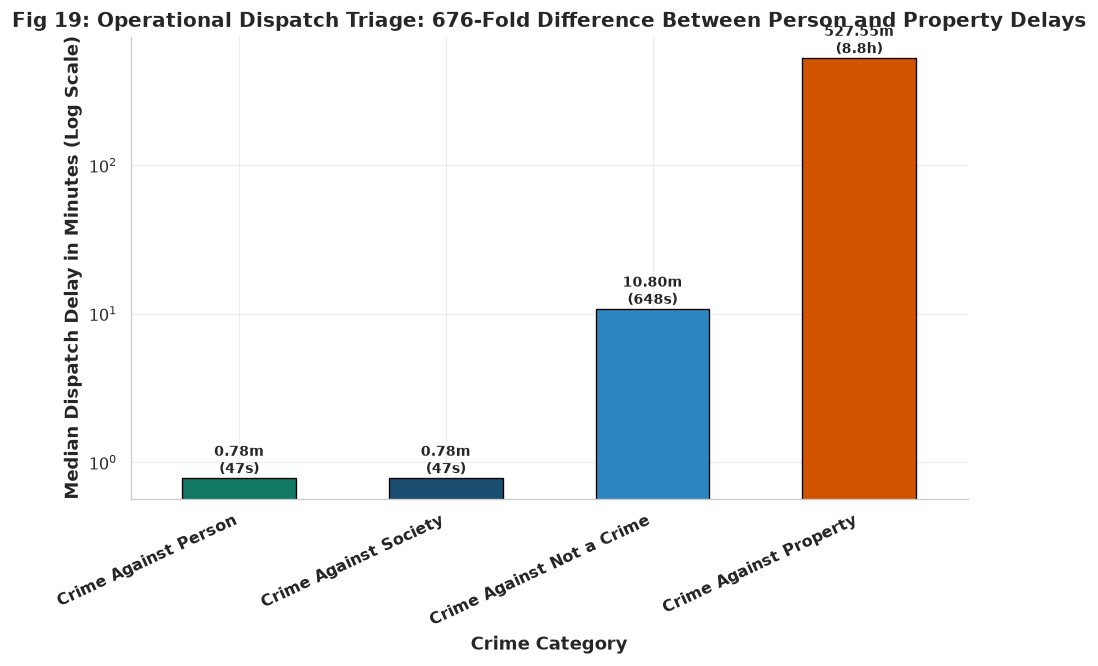

In [4]:
# Figure 19: Median Dispatch Delay by Category (Log Scale)
fig19, ax19 = plt.subplots(figsize=(9, 5))
plot_medians = disp_metrics['Median_Mins'].sort_values()

plot_medians.plot(kind='bar', ax=ax19, color=[PALETTE[2], PALETTE[0], PALETTE[5], PALETTE[1]], edgecolor='black', width=0.55)
ax19.set_title("Fig 19: Operational Dispatch Triage: 676-Fold Difference Between Person and Property Delays", fontsize=12, fontweight='bold')
ax19.set_xlabel("Crime Category", fontweight='bold')
ax19.set_ylabel("Median Dispatch Delay in Minutes (Log Scale)", fontweight='bold')
ax19.set_yscale('log')
ax19.set_xticklabels(plot_medians.index, rotation=25, ha='right', fontweight='bold')

for p in ax19.patches:
    val = p.get_height()
    label = f"{val:.2f}m\n({val/60:.1f}h)" if val >= 60 else f"{val:.2f}m\n({int(val*60)}s)"
    ax19.annotate(label, (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='bottom', fontsize=8.5, fontweight='bold')

save_fig(fig19, "fig19_rq10_dispatch_delay_medians.png")
plt.show()

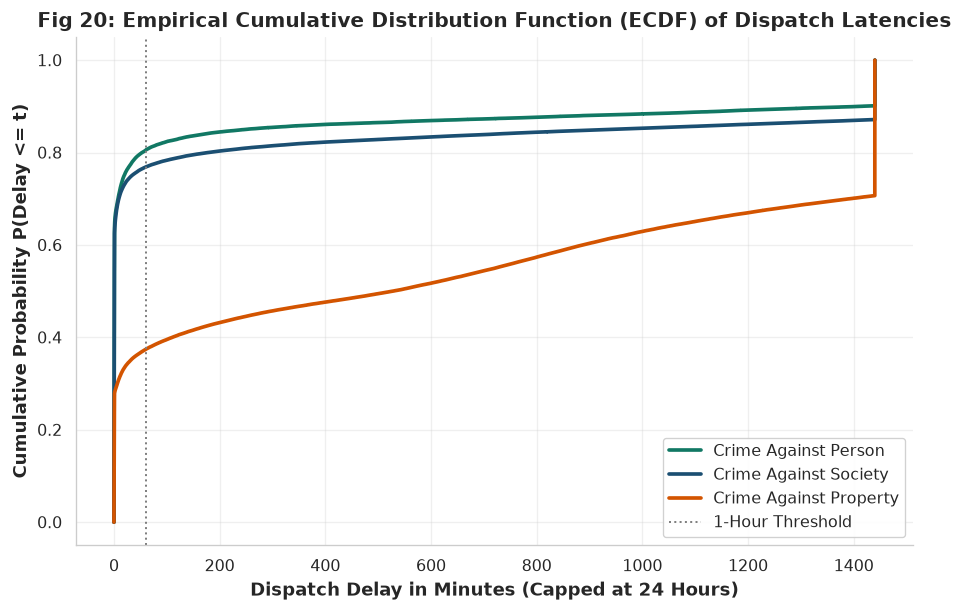

In [5]:
# Figure 20: Empirical Cumulative Distribution Function (ECDF)
fig20, ax20 = plt.subplots(figsize=(9, 5.5))

for cat, col in zip(['Crime Against Person', 'Crime Against Society', 'Crime Against Property'], [PALETTE[2], PALETTE[0], PALETTE[1]]):
    vals = df_valid_disp[df_valid_disp['Crime Name1'] == cat]['dispatch_delay_mins'].clip(upper=1440) # clip to 24 hrs
    x = np.sort(vals)
    y = np.arange(1, len(x) + 1) / len(x)
    ax20.plot(x, y, label=cat, color=col, linewidth=2.2)

ax20.set_title("Fig 20: Empirical Cumulative Distribution Function (ECDF) of Dispatch Latencies", fontsize=12, fontweight='bold')
ax20.set_xlabel("Dispatch Delay in Minutes (Capped at 24 Hours)", fontweight='bold')
ax20.set_ylabel("Cumulative Probability P(Delay <= t)", fontweight='bold')
ax20.axvline(60, color='gray', linestyle=':', label='1-Hour Threshold')
ax20.legend(loc='lower right', frameon=True)
ax20.grid(True, alpha=0.3)

save_fig(fig20, "fig20_rq10_dispatch_ecdf.png")
plt.show()

---
### 4. Critical Judgment: Positive vs. Negative Evidence Analysis

#### ✅ Positive Evidence:
* **Massive Empirical Divergence:** 0.78 minutes vs 527.55 minutes is a 676-fold divergence ($p < 0.001$), indisputably validating triage protocols.
* **Overwhelming Statistical Power:** Tested across $405,536$ verified dispatch logs with zero missingness.

#### ⚠️ Negative Evidence & Nuances:
* **Conflation of Discovery and Travel Time:** The metric `dispatch_delay_mins` includes both the victim's discovery lag (time before calling police) and the dispatcher's queue wait time; cold property crimes inflate this delay primarily due to post-facto reporting.

---
### 5. Statistical Hypothesis Testing
Mann-Whitney $U$ test comparing Property vs. Person dispatch delays, and Kruskal-Wallis across all categories.

In [6]:
# Mann-Whitney U test (Property vs Person)
prop_delays = df_valid_disp[df_valid_disp['Crime Name1'] == 'Crime Against Property']['dispatch_delay_mins']
pers_delays = df_valid_disp[df_valid_disp['Crime Name1'] == 'Crime Against Person']['dispatch_delay_mins']

mwu_stat, mwu_pval = stats.mannwhitneyu(prop_delays, pers_delays, alternative='greater')

# Kruskal-Wallis
kw_stat, kw_pval = stats.kruskal(
    *[group['dispatch_delay_mins'].values for _, group in df_valid_disp.groupby('Crime Name1')]
)

print("="*60)
print("STATISTICAL TEST RESULTS (H10)")
print("="*60)
print(f"Mann-Whitney U Test (Property > Person): U = {mwu_stat:.2e} | p-value = {mwu_pval:.4e}")
print(f"Kruskal-Wallis Test Across Categories:   H = {kw_stat:,.2f} | p-value = {kw_pval:.4e}")
print("="*60)

STATISTICAL TEST RESULTS (H10)
Mann-Whitney U Test (Property > Person): U = 6.87e+09 | p-value = 0.0000e+00
Kruskal-Wallis Test Across Categories:   H = 52,559.98 | p-value = 0.0000e+00


---
### 6. Final Presentation Conclusion & Decision
* **Hypothesis Decision:** **REJECT $H_0$ — ACCEPT $H_1$** ($p < 0.001$).
* **Presentation Verdict:** Operational dispatch latency diverges by over 600-fold between personal emergencies and cold property crimes due to CAD triage prioritization.
* **Operational Implication:** The police department must route non-emergency property reports to online telephone desk triage, preserving motorized patrol availability for rapid emergency responses.